In [6]:
%pip install -q "qiskit==2.2.3" "qiskit-algorithms==0.4.0" "qiskit-nature==0.7.2" "pyscf==2.10.0"

import sys
from importlib.metadata import version
print("Python:", sys.version.split()[0])
for package in ["qiskit", "qiskit-algorithms", "qiskit-nature", "pyscf", "numpy", "scipy", "scikit-learn"]:
    print(package, version(package))
print("설치 완료: 다음 실행 코드 셀로 이동합니다.")

Python: 3.13.16
qiskit 2.2.3
qiskit-algorithms 0.4.0
qiskit-nature 0.7.2
pyscf 2.10.0
numpy 2.1.3
scipy 1.16.3
scikit-learn 1.6.1
설치 완료: 다음 실행 코드 셀로 이동합니다.


Running QAOA Optimization...

Optimization Results & Verification
선택 비트열(q3…q0) : 1010
선택 해의 Cut      : 4 / 전수 탐색 최댓값: 4
분포의 평균 에너지 : -3.428223
최적 Cut의 관측 확률: 0.4341
검증 통과: QAOA가 정확한 최적 MaxCut 해를 찾아냈습니다.


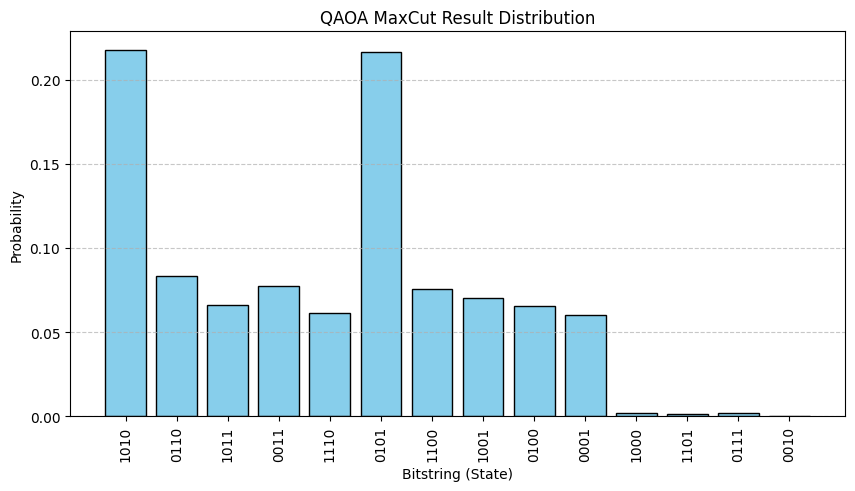

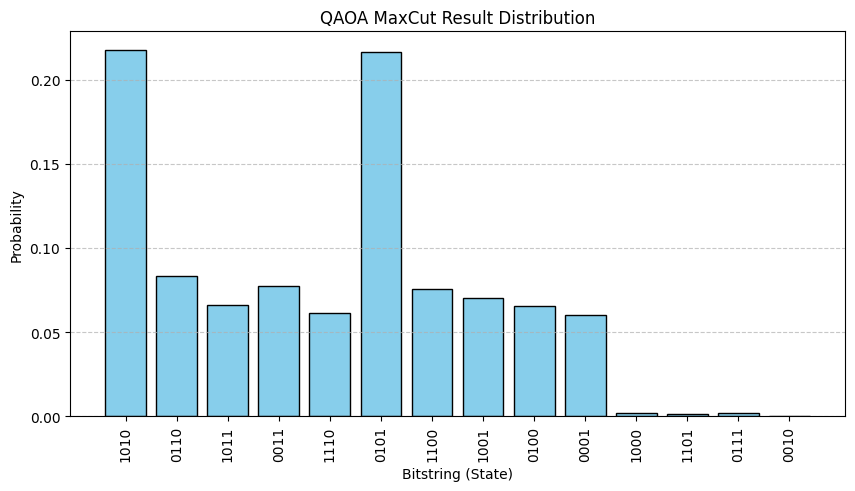

In [7]:
%matplotlib inline

# ==============================================================================
# STEP 1. 라이브러리 임포트 및 경고 설정
# ==============================================================================
# 양자 계산, 시각화, 파울리 연산자, 샘플러 프리미티브,
# QAOA 알고리즘 및 고전 최적화기(COBYLA)를 불러옵니다.
import numpy as np
import matplotlib.pyplot as plt

from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives import StatevectorSampler

from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA

import warnings
from scipy.sparse import SparseEfficiencyWarning
warnings.filterwarnings("ignore", category=SparseEfficiencyWarning)


# ==============================================================================
# STEP 2. MaxCut 그래프 문제 정의
# ==============================================================================
# 4개의 노드(n=4)와 5개의 간선(edges)으로 구성된 그래프를 정의합니다.
# 목적: 그래프를 두 그룹으로 나누어 그룹 사이의 간선(Cut) 수를 최대화합니다.
edges = [(0, 1), (1, 2), (2, 3), (3, 0), (0, 2)]
n = 4


# ==============================================================================
# STEP 3. MaxCut 해밀턴산(Hamiltonian) 구성
# ==============================================================================
# MaxCut 문제는 최소 고유값(Ground State)을 찾는 VQE/QAOA의 성질을 이용하기 위해,
# 컷(Cut) 값에 마이너스(-)를 붙인 비용 해밀턴산(Cost Hamiltonian) H를 구성합니다.
terms = [("I" * n, -len(edges) / 2)]

for i, j in edges:
    label = ["I"] * n
    # Qiskit 규칙에 따라 오른쪽 문자가 큐비트 0을 의미하므로 인덱스를 역순으로 매핑합니다.
    label[n - 1 - i] = label[n - 1 - j] = "Z"
    terms.append(("".join(label), 0.5))

H = SparsePauli.from_list(terms) if 'SparsePauli' in globals() else SparsePauliOp.from_list(terms)


# ==============================================================================
# STEP 4. QAOA 알고리즘 초기화 및 설정
# ==============================================================================
# - StatevectorSampler: 이상적인 양자 측정 확률 분포를 샘플링하는 프리미티브
# - COBYLA: 파라미터(감마, 베타)를 조정하는 고전 최적화기
# - reps=2: QAOA 회로의 레이어 반복 횟수 (깊이)
# - initial_point: 초기 각도 설정 [0.2, 0.4, 0.6, 0.8]
qaoa = QAOA(
    sampler=StatevectorSampler(default_shots=2048, seed=42),
    optimizer=COBYLA(maxiter=120),
    reps=2,
    initial_point=[0.2, 0.4, 0.6, 0.8]
)


# ==============================================================================
# STEP 5. QAOA 최적화 실행 (최적 파라미터 탐색)
# ==============================================================================
# 해밀턴산(H)을 입력하여 QAOA 최적화를 수행하고 최적의 상태와 측정 결과를 얻습니다.
print("=" * 60)
print("Running QAOA Optimization...")
print("=" * 60)

result = qaoa.compute_minimum_eigenvalue(H)


# ==============================================================================
# STEP 6. 결과 분석 및 정답(Exact) 비교
# ==============================================================================
# 비트열 상태별 Cut 값을 계산하는 함수 정의
def cut(z):
    return sum(((z >> i) & 1) != ((z >> j) & 1) for i, j in edges)

# 측정된 결과에서 비트열과 확률 분포 추출
counts = {int(z, 2) if isinstance(z, str) else int(z): float(p) for z, p in result.eigenstate.items()}
observed = [int(z) for z, prob in counts.items() if prob > 0]

# QAOA가 찾은 최적의 비트열과 브루트포스(전수 탐색)를 통한 이론상 최댓값 비교
best = max(observed, key=cut)
exact = max(cut(z) for z in range(2**n))

print("\n" + "=" * 60)
print("Optimization Results & Verification")
print("=" * 60)
print(f"선택 비트열(q3…q0) : {format(best, '04b')}")
print(f"선택 해의 Cut      : {cut(best)} / 전수 탐색 최댓값: {exact}")
print(f"분포의 평균 에너지 : {round(float(result.eigenvalue.real), 6)}")
print(f"최적 Cut의 관측 확률: {round(sum(p for z, p in counts.items() if cut(int(z)) == exact), 4)}")

# 결과 검증
assert cut(best) == exact, "QAOA가 최적의 MaxCut 해를 찾지 못했습니다!"
print("검증 통과: QAOA가 정확한 최적 MaxCut 해를 찾아냈습니다.")


# ==============================================================================
# STEP 7. 결과 시각화 (확률 분포 바 차트)
# ==============================================================================
# 관측된 모든 비트열 상태와 그에 해당하는 측정 확률을 바 차트로 시각화합니다.
fig = plt.figure(figsize=(10, 5))

bitstring_labels = [format(int(z), "04b") for z in counts]
probabilities = list(counts.values())

plt.bar(bitstring_labels, probabilities, color='skyblue', edgecolor='black')
plt.xlabel("Bitstring (State)")
plt.ylabel("Probability")
plt.title("QAOA MaxCut Result Distribution")
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)

display(fig)
plt.show()